# CE1110 — Tarea 1: Análisis de señales y filtrado
**Grupo 03** · Josué Pérez, Marcelo Matey, Jorge Porras

Este notebook regenera desde cero todas las señales, resultados, figuras y métricas de la tarea. Cada sección llama al código de `src/`, por lo que el notebook solo orquesta la ejecución y muestra los resultados principales.

**Cómo ejecutarlo:** abrir este archivo desde la carpeta `tarea1_grupo03/` y usar *Restart* → *Run All*.

**Requisitos:** Python 3.11 con `numpy`, `scipy`, `matplotlib` e `ipykernel`.

## 0. Configuración

In [1]:
import sys
import csv
import json
import runpy
import os
from pathlib import Path
from unittest import mock

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Raiz del proyecto: la carpeta donde esta este notebook
RAIZ = Path.cwd()
SRC = RAIZ / "src"
PRUEBAS = RAIZ / "pruebas"
FIGURAS = RAIZ / "resultados" / "figuras"
CONFIG = RAIZ / "metadatos" / "configuraciones.json"

if not SRC.is_dir():
    raise RuntimeError(f"Abra el notebook desde la carpeta tarea1_grupo03/ (carpeta actual: {RAIZ})")

FIGURAS.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC))   # permite importar los modulos de src/

print("Python:", sys.executable)
print("Raiz del proyecto:", RAIZ)

Python: C:\Users\josue\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe
Raiz del proyecto: c:\Users\josue\Documents\proyectos\jalvarado_asm_2026_s2\tarea1_grupo03


In [2]:
def correr_script(nombre):
    """Ejecuta un script de src/ como si se corriera con `python nombre` desde src/.

    - Cambia temporalmente a src/ porque varios scripts usan rutas relativas
      como ../pruebas y ../resultados.
    - Desactiva plt.show() mientras corre, para que el notebook no se llene con
      todas las figuras intermedias; las figuras quedan guardadas en
      resultados/figuras/ y abajo se muestran las principales.
    """
    carpeta_original = Path.cwd()
    os.chdir(SRC)
    try:
        with mock.patch.object(plt, "show", lambda *a, **k: None):
            runpy.run_path(str(SRC / nombre), run_name="__main__")
    finally:
        plt.close("all")
        os.chdir(carpeta_original)


def mostrar(*nombres, ancho=700):
    """Muestra figuras guardadas en resultados/figuras/."""
    for n in nombres:
        display(Image(filename=str(FIGURAS / n), width=ancho))

## 1. Generación reproducible de las señales de prueba (2.2a y 2.2b)

Los tres casos se regeneran a partir de `metadatos/configuraciones.json` (semilla y parámetros de cada caso) con `src/generador.py`, que contiene las funciones del notebook del profesor. Con la misma semilla se obtienen archivos idénticos a los originales.

**Parámetros comunes:** $f_s = 16$ kHz, 6 s de duración (96 000 muestras), multitono con componentes útiles de 440, 880 y 1320 Hz (amplitudes 1, 0.55 y 0.3; fases 0°, 35° y −50°).

| Caso | Ruido | Semilla | SNR objetivo | Por qué se eligió |
| --- | --- | --- | --- | --- |
| 1 | Tonal (interferencia en 1750 Hz) | 2026105 | 5 dB | Interferencia separada de los tonos útiles (el más cercano, 1320 Hz, está a 430 Hz). Es el caso donde un filtro notch fijo debería funcionar. |
| 2 | Blanco | 2026104 | 5 dB | El ruido ocupa todo el espectro y no tiene una frecuencia que atacar; prueba qué hace cada método sin una estructura clara. |
| 3 | Banda limitada (500–1500 Hz) | 2026106 | 3 dB | La banda de ruido se superpone con los tonos de 880 y 1320 Hz, por lo que reducir ruido obliga a dañar señal útil. |

La SNR obtenida se calcula como $\mathrm{SNR}_{\mathrm{dB}} = 10\log_{10}\dfrac{\sum s^2[n]}{\sum (x[n]-s[n])^2}$ y coincide con la configurada salvo errores de redondeo (del orden de $10^{-14}$ dB).

In [3]:
import generador

configuraciones = generador.cargar_configuraciones(CONFIG)

print(f"{'caso':8s} {'señal':10s} {'ruido':8s} {'semilla':>9s} {'SNR obj':>8s} {'SNR obt':>10s} {'dif':>9s}")
for cfg in configuraciones:
    meta = generador.exportar_caso(cfg, PRUEBAS / cfg["nombre_prueba"])
    dif = meta["snr_obtenida_dB"] - meta["snr_objetivo_dB"]
    print(f"{meta['nombre_prueba']:8s} {meta['tipo_senal']:10s} {meta['tipo_ruido']:8s} {meta['semilla']:>9d} "
          f"{meta['snr_objetivo_dB']:>8.2f} {meta['snr_obtenida_dB']:>10.4f} {dif:>9.1e}")

caso     señal      ruido      semilla  SNR obj    SNR obt       dif
caso_1   multitono  tonal      2026105     5.00     5.0000   1.3e-14
caso_2   multitono  blanco     2026104     5.00     5.0000   8.0e-15
caso_3   multitono  banda      2026106     3.00     3.0000   2.7e-14


## 2. Implementación de la FFT (2.1)

Se usa una FFT implementada por el grupo (módulo `DFT`) para analizar la magnitud y la fase de tonos de prueba con $f_s = 16$ kHz y $N = 1024$ muestras, por lo que la separación entre bins es $\Delta f = f_s/N = 15.625$ Hz.

- **Resolución, latencia y memoria.** Para $N = 256, 512, 1024$ y $4096$ se calculan $\Delta f$, la duración del bloque $T = N/f_s$ y la memoria del espectro complejo en `float32` ($8N$ bytes). Al aumentar $N$ mejora la resolución (de 62.5 a 3.9 Hz) pero crecen la latencia (de 16 a 256 ms) y la memoria (de 2 a 32 KiB).
- **Fuga espectral.** Se comparan un tono de 1000 Hz, que cae exactamente en el bin $k = 64$, y uno de 1100 Hz, que cae en $k = 70.4$ (entre bins), con ventana rectangular y de Hann. Con el tono en un bin exacto la energía se concentra en un solo bin; con el tono entre bins se fuga hacia los vecinos con lóbulos laterales que decaen lento. La ventana de Hann reduce esos lóbulos laterales a costa de un lóbulo principal más ancho.
- **Simetría conjugada.** Para una señal real se cumple $X[N-k] = X^*[k]$; el máximo error medido fue de $3.8\times10^{-14}$. Al modificar un solo bin sin su espejo, la IFFT deja de ser real (parte imaginaria máxima de $0.499$); al corregir el espejo vuelve a nivel de redondeo ($6.6\times10^{-17}$). Por eso cualquier ganancia aplicada al espectro debe ser real y simétrica.
- **Magnitud y fase.** Con un desfase conocido $\varphi = 35^\circ$, la fase medida en el bin 64 es $35.0000^\circ$, lo que valida la implementación. La fase solo se grafica donde la magnitud supera el 1 % del máximo; en el resto es ruido numérico.

Muestras: 256
df: 62.5
duracion: 0.016
memoria: 2.0
Muestras: 512
df: 31.25
duracion: 0.032
memoria: 4.0
Muestras: 1024
df: 15.625
duracion: 0.064
memoria: 8.0
Muestras: 4096
df: 3.90625
duracion: 0.256
memoria: 32.0
maximo error entre k y N - k para todo k = 0, 1, ... , N:
6.472853678771412e-14
destruccion de simetria: 
maximo valor imaginario de la inversa: 
0.49902343750000017
arreglo de simetria
maximo valor imaginario de la inversa: 
6.976485045910019e-17
fase en el bin 64 [grados]: 34.99999999999911


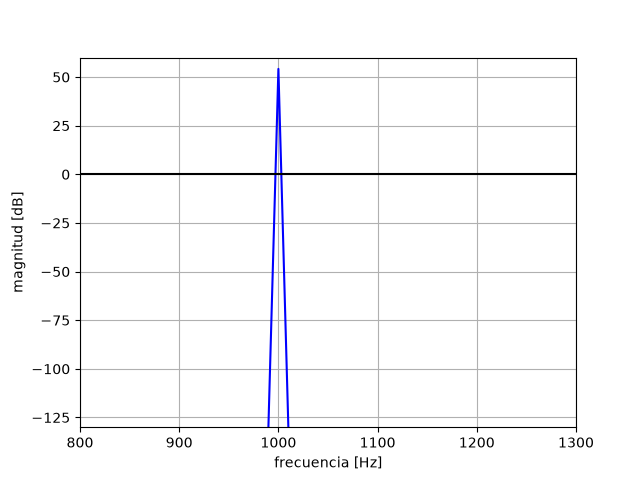

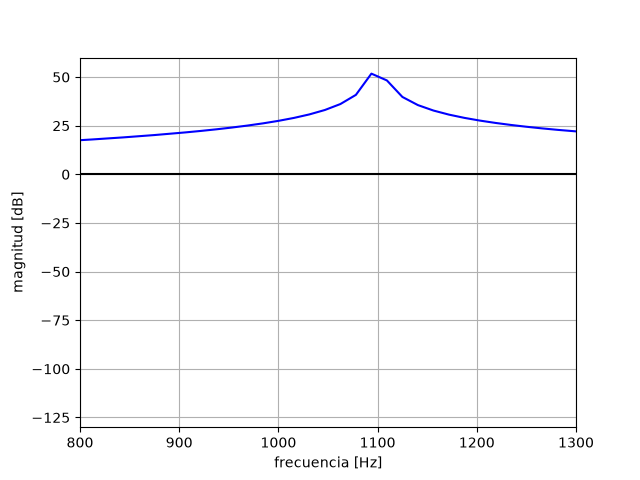

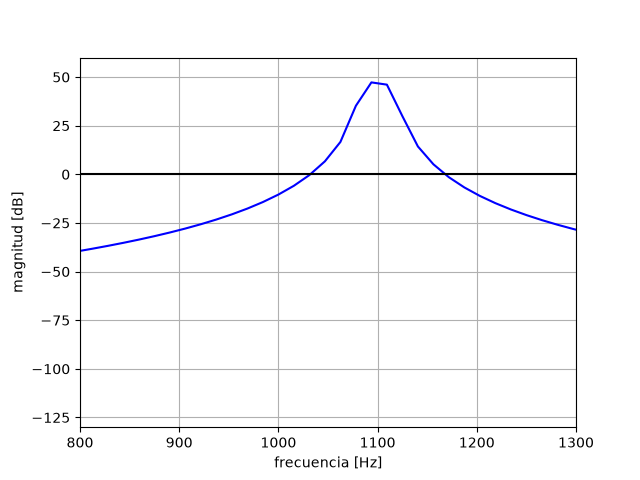

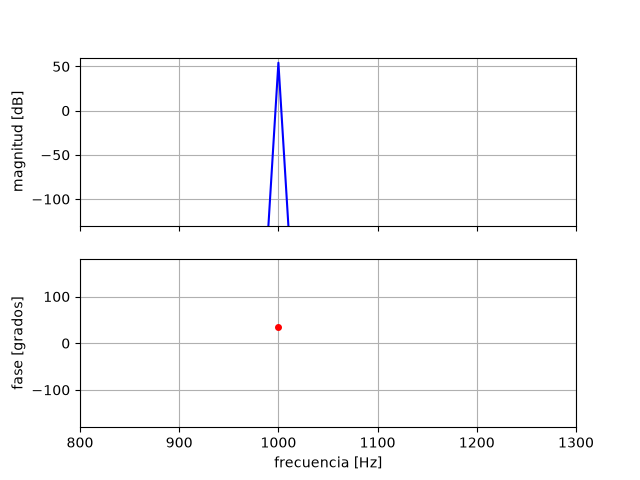

In [4]:
correr_script("analisis_2.1.py")
mostrar("1000_mag_FFT.png", "1100_mag_FFT.png", "1100_hann_mag_FFT.png", "1000_mag_fase.png")

## 3. Caracterización de las señales (2.2c a 2.2e)

Para cada caso se calcula el espectro con ventana de Hann sobre $N = 32768$ muestras tomadas desde $t = 1$ s (para evitar el transitorio inicial) y se grafica:

- **Energía por banda.** La energía de la señal limpia y del ruido en bandas de 500 Hz, en dB.
- **SNR por banda.** $10\log_{10}(E_{\text{limpia}}/E_{\text{ruido}})$ por banda. En el caso 1 es muy alta en las bandas con señal y negativa solo en la de 1.5–2.0 kHz, donde únicamente hay interferencia. En el caso 2 es positiva donde está la señal (15.3, 10.6 y 5.1 dB en las tres primeras bandas). En el caso 3 cae a −0.6 y −5.6 dB en 0.5–1.0 y 1.0–1.5 kHz, donde el ruido se superpone con los tonos útiles.
- **Fase.** Del espectro de la señal limpia y de la contaminada, enmascarando los bins sin energía.

**Características para identificar el ruido automáticamente.** Se calculan dos medidas sobre el espectro de potencia del ruido: la relación pico/mediana y la planitud espectral (media geométrica sobre media aritmética):

| Caso | Pico/mediana | Planitud |
| --- | --- | --- |
| 1 (tonal) | 236.6 dB | 0.000 |
| 2 (blanco) | 11.9 dB | 0.560 |
| 3 (banda) | 98.1 dB | 0.000 |

El ruido blanco se reconoce por su planitud alta. Los casos 1 y 3 tienen planitud cercana a 0, así que además se necesita medir qué tan concentrada está la energía: en el caso 1 es un solo pico (1750 Hz) y en el caso 3 es una banda contigua (500–1500 Hz).

**Información no recuperable.** Donde señal y ruido comparten bins solo se observa $X[k] = S[k] + V[k]$; una ganancia por bin escala ambos términos, así que reducir el ruido implica reducir también la señal en ese bin.

caso_1: SNR por banda [dB] (solo las 4 primeras bandas)
   0.0-0.5 kHz: 104.8
   0.5-1.0 kHz: 113.5
   1.0-1.5 kHz: 107.2
   1.5-2.0 kHz: -93.8
   pico/mediana = 236.6 dB | planitud espectral = 0.000
caso_2: SNR por banda [dB] (solo las 4 primeras bandas)
   0.0-0.5 kHz: 15.3
   0.5-1.0 kHz: 10.6
   1.0-1.5 kHz: 5.1
   1.5-2.0 kHz: -78.0
   pico/mediana = 11.9 dB | planitud espectral = 0.560
caso_3: SNR por banda [dB] (solo las 4 primeras bandas)
   0.0-0.5 kHz: 24.5
   0.5-1.0 kHz: -0.6
   1.0-1.5 kHz: -5.6
   1.5-2.0 kHz: -71.0
   pico/mediana = 98.1 dB | planitud espectral = 0.000


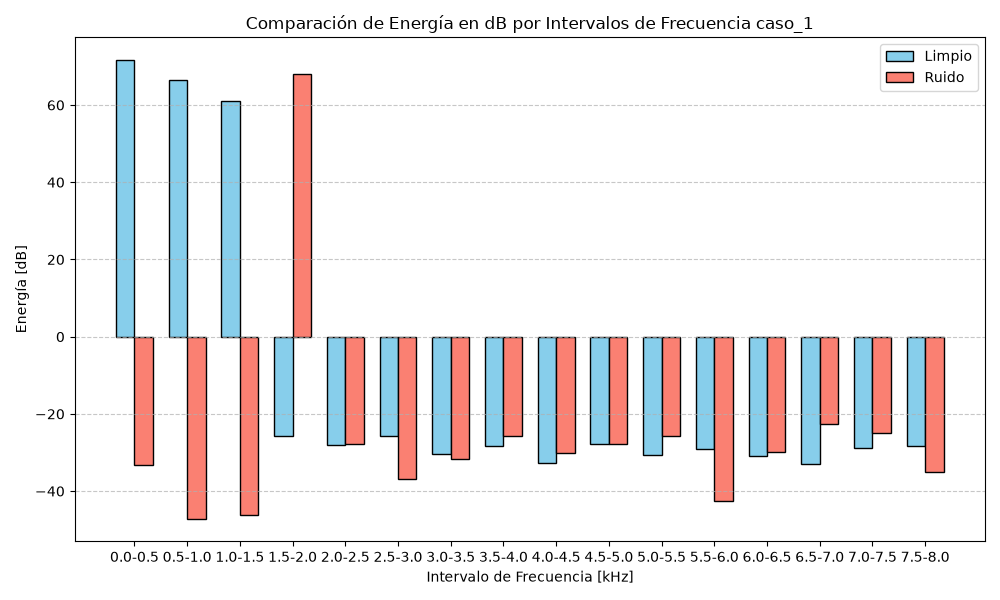

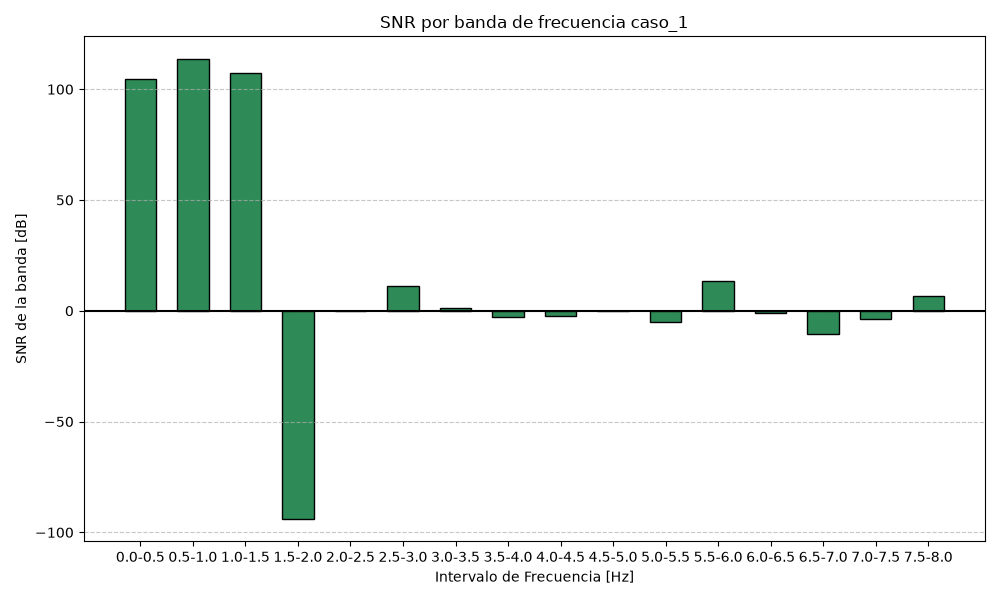

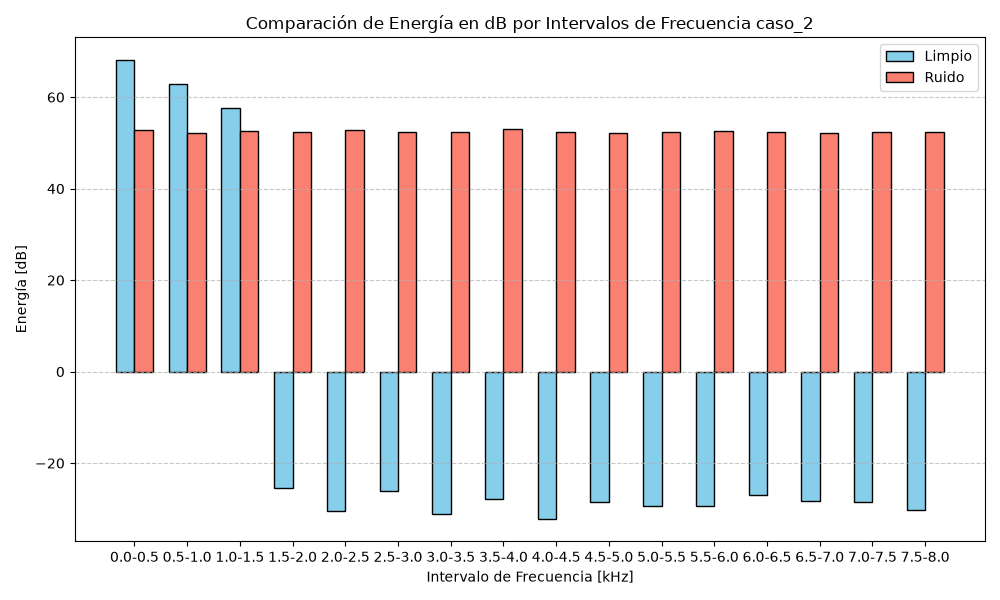

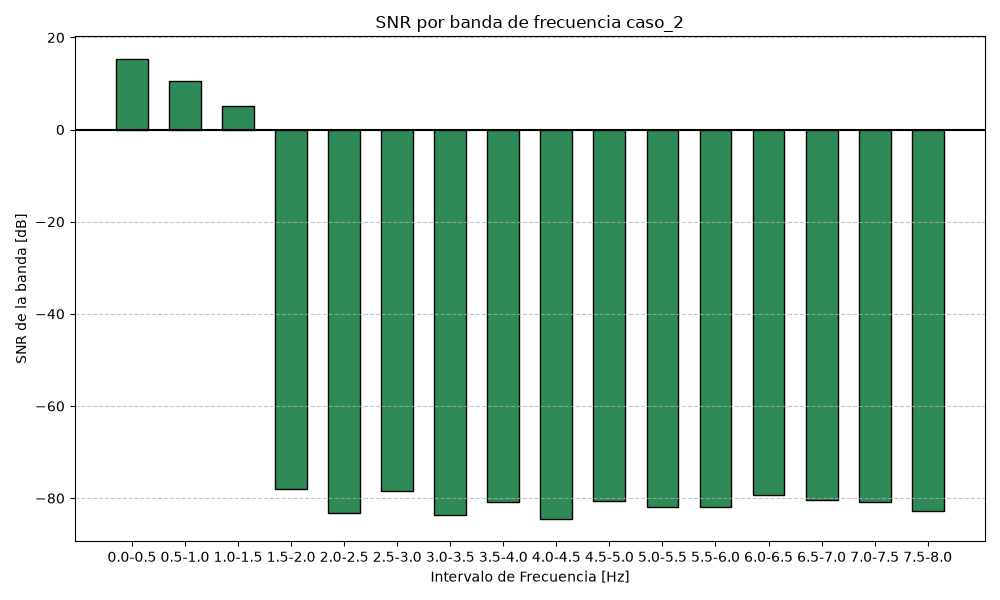

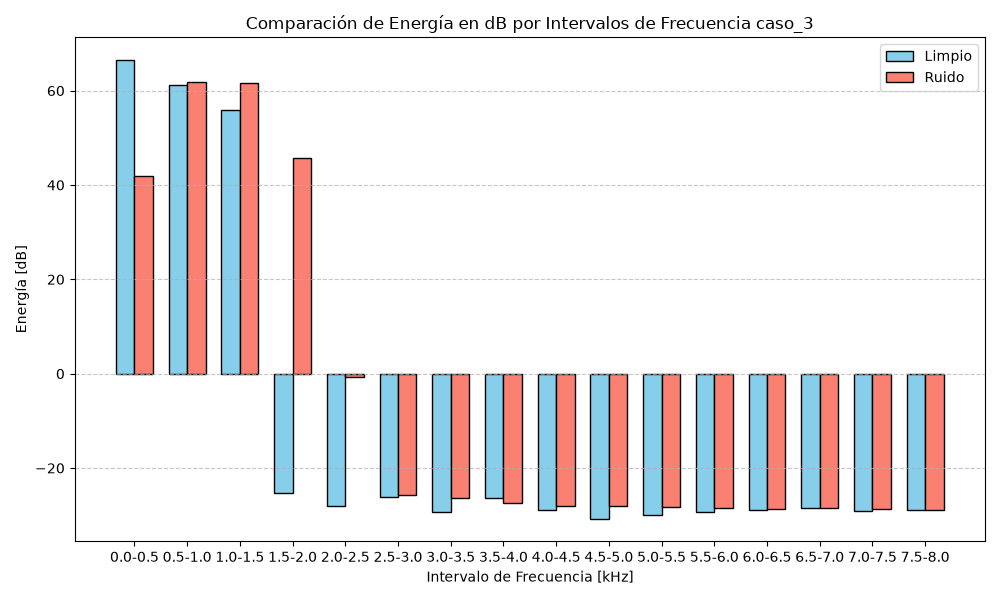

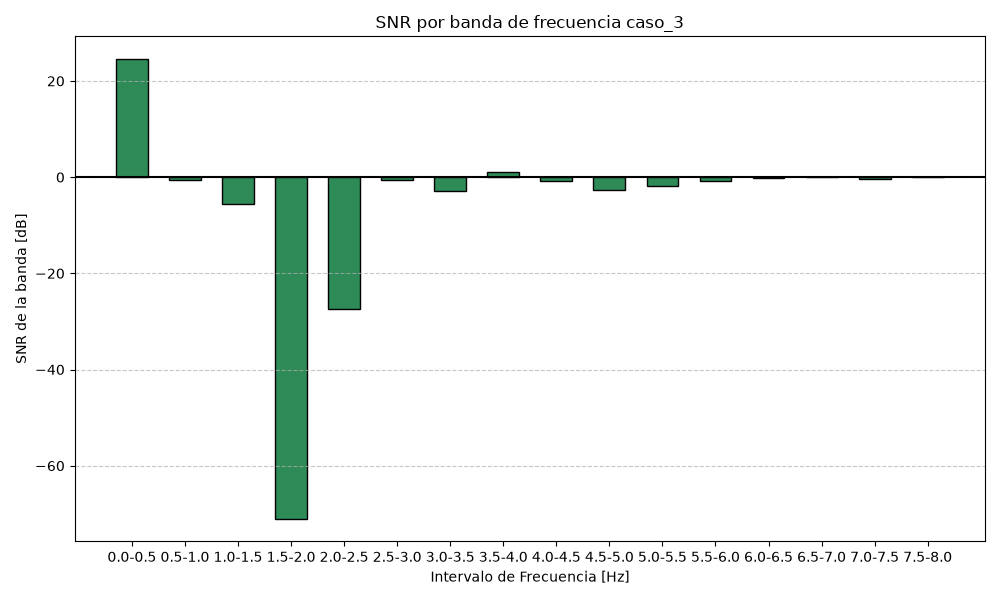

In [5]:
correr_script("analisis_2.2.py")
for caso in ["caso_1", "caso_2", "caso_3"]:
    mostrar(f"{caso}_energia.png", f"{caso}_snr_banda.png")

## 4. Filtro temporal: notch IIR (2.3)

Se diseñó para el **caso 1** un filtro de rechazo de banda estrecha (*notch*) IIR de segundo orden con `scipy.signal.iirnotch`, con $f_0 = 1750$ Hz y $Q = 10$ (ancho de banda a −3 dB de $f_0/Q = 175$ Hz). Se eligió porque la interferencia es una sola frecuencia aislada de los tonos útiles; un IIR de orden 2 la rechaza con 5 coeficientes y 4 estados.

**Coeficientes:** $b = [0.96677,\ -1.49464,\ 0.96677]$, $a = [1,\ -1.49464,\ 0.93354]$, con

$$H(z) = \frac{0.96677 - 1.49464\,z^{-1} + 0.96677\,z^{-2}}{1 - 1.49464\,z^{-1} + 0.93354\,z^{-2}}$$

y ecuación de diferencias $y[n] = b_0x[n] + b_1x[n-1] + b_2x[n-2] - a_1y[n-1] - a_2y[n-2]$.

**Polos y ceros.** Los ceros están sobre el círculo unitario en $z = e^{\pm j\omega_0}$ y los polos en $|p| = 0.9662$. Como el filtro es causal, la región de convergencia es $|z| > 0.9662$, que incluye al círculo unitario, por lo que es estable.

**Verificación.** La ecuación de diferencias implementada por el grupo coincide con `scipy.signal.lfilter` con un error máximo de $6.7\times10^{-16}$.

**Aplicación a los tres casos** (segmento desde $t = 1$ s):

| Caso | SNR entrada | SNR salida | $\Delta$SNR |
| --- | --- | --- | --- |
| 1 (tonal) | 5.01 dB | 24.46 dB | +19.45 dB |
| 2 (blanco) | 5.02 dB | 5.11 dB | +0.10 dB |
| 3 (banda) | 3.03 dB | 3.07 dB | +0.04 dB |

El filtro elimina la interferencia del caso 1, pero casi no cambia nada en los casos 2 y 3 porque su ruido no está en 1750 Hz.

**Cuantización de coeficientes.** Con `float32` y con punto fijo $Q2.12$ la SNR de salida del caso 1 no cambia (24.46 dB). La degradación aparece en $Q2.8$: la atenuación en 1750 Hz cae a −19.6 dB y la SNR a 21.42 dB. El filtro se mantiene estable en todos los formatos, ya que los polos siguen dentro del círculo unitario. La memoria es de 36 B en `float32`.

coeficientes a: 1.0, -1.4946430028885405, 0.9335353052297932
coeficientes b: 0.9667676526148966, -1.4946430028885405, 0.9667676526148966
|polos| = [0.96619631 0.96619631]
estable: True
error maximo propia vs lfilter: 6.661338147750939e-16
SNR entrada: 5.007133148911792
SNR salida : 24.4557387482405
caso      SNR_in   SNR_out   dSNR     MSE_in       MSE_out
caso_1     5.01    24.46    19.45   3.15e-02   3.57e-04
caso_2     5.02     5.11     0.10   1.39e-02   1.36e-02
caso_3     3.03     3.07     0.04   1.51e-02   1.50e-02

formato    max|p|    estable   gan.1750Hz   gan.1320Hz   SNR_out(caso 1)
float64    0.96620   True        -240.0 dB     -0.136 dB    24.46
float32    0.96620   True        -117.7 dB     -0.136 dB    24.46
Q2.14      0.96619   True         -57.0 dB     -0.133 dB    24.46
Q2.12      0.96623   True         -57.0 dB     -0.135 dB    24.46
Q2.10      0.96623   True         -39.8 dB     -0.136 dB    24.41
Q2.8       0.96623   True         -19.6 dB     -0.300 dB    21.42


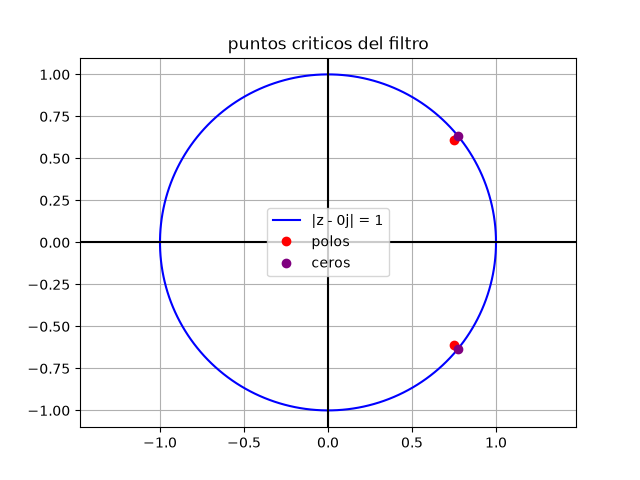

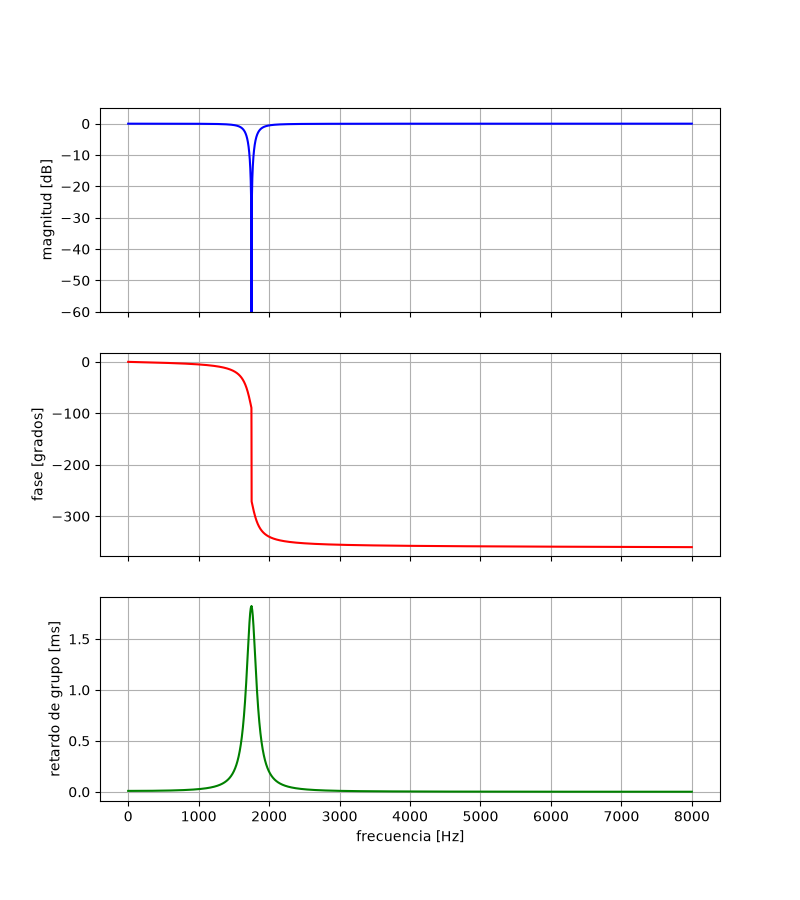

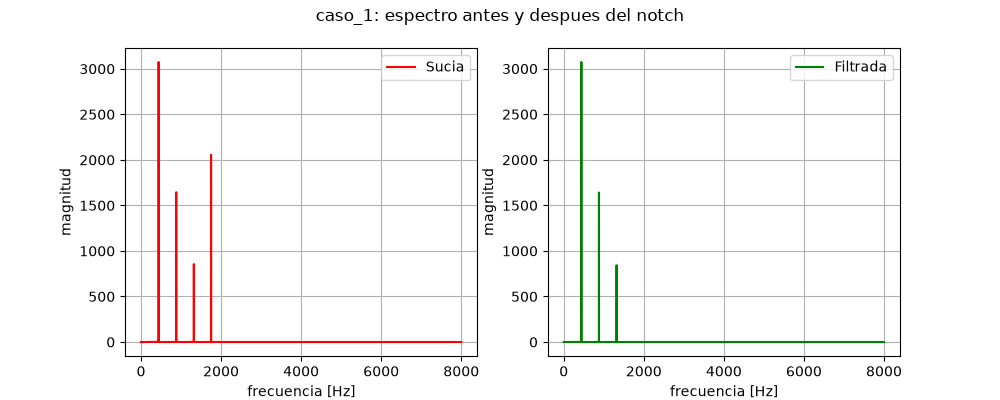

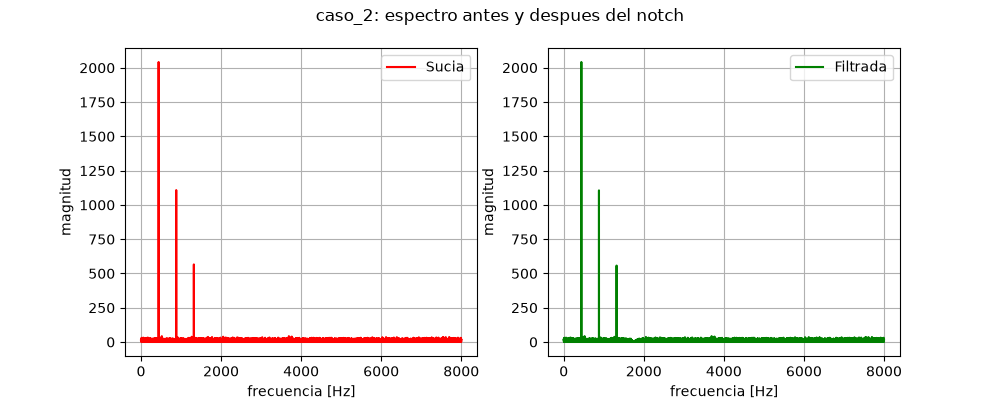

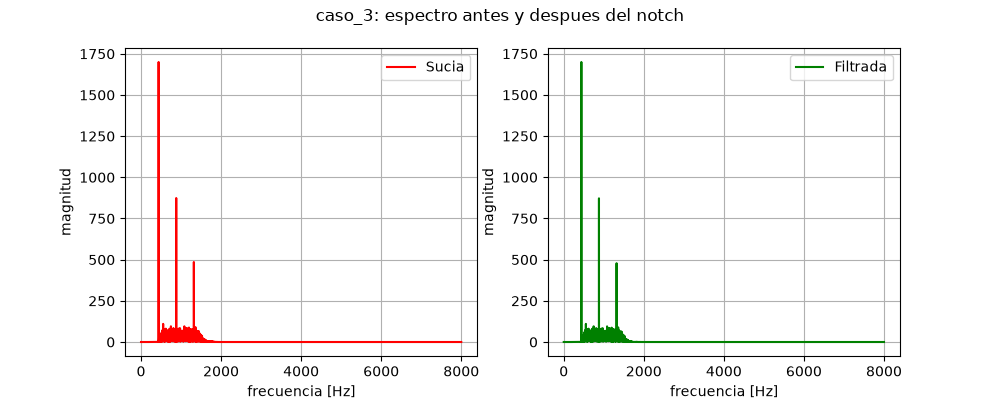

In [6]:
correr_script("filtrado_temporal.py")
mostrar("filtro_puntos.png", "filtro_respuesta.png")
for caso in ["caso_1", "caso_2", "caso_3"]:
    mostrar(f"{caso}_antes_despues.png")

## 5. Filtrado espectral por bloques: FFT/IFFT (2.4)

### 5.1 Resumen del método

Se utilizo una ganancia de Wiener con estimación de ruido por bin y con memoria entre bloques,
más un notch que atenúa picos intensos fuera de la banda útil.
La frecuencia de la interferencia no se fija a mano: sale de la detección de
picos en cada bloque. Lo único que se declara como suposición es la banda útil.

Cadena por bloque (código: `procesar` en `src/filtrado_espectral.py`):

    bloque -> ventana (raíz de Hann) -> rfft -> ganancia G[k] -> irfft
           -> ventana (raíz de Hann) -> suma con solapamiento -> salida

Parámetros fijos del procesamiento:

| Parámetro | Valor | Consecuencia |
|---|---|---|
| fs | 16 000 Hz | |
| N (potencia de dos) | 1024 | Duración de bloque N/fs = 64 ms |
| hop | 512 (solapamiento 50 %) | Avance de 32 ms |
| Separación entre bins | fs/N = 15.625 Hz | Resolución frecuencial |

### 5.2 Ventana, solapamiento y reconstrucción

- Se usa la raíz de Hann como ventana de análisis y de síntesis. Su producto es
  una ventana Hann, que con hop = N/2 suma 1 (propiedad COLA), así que sin
  modificar el espectro la salida reproduce la entrada.
- Se aplica también ventana de síntesis para suavizar las discontinuidades que
  introduce modificar el espectro en los bordes de cada bloque.
- Se antepone y se agrega relleno de ceros para que todas las muestras queden
  cubiertas por dos ventanas, y se recorta al final para alinear con la entrada.

### 5.3 Simetría conjugada

Se usa `rfft`/`irfft`: solo se procesan N/2 + 1 bins (0 a fs/2) y la
reconstrucción impone la simetría X[N-k] = conj(X[k]) de forma automática.
La ganancia G es real y no negativa, por lo que modifica magnitudes sin alterar
la fase y la salida es real.

### 5.4 Estimación de ruido (parámetro adaptativo)

Para cada bloque se calcula la potencia P[k] = |X[k]|^2 y se estima el ruido
en dos pasos:

1. Mediana móvil a lo largo de la frecuencia (ventana de 31 bins), dividida
   entre ln 2 para corregir el sesgo de la mediana respecto a la media en ruido
   gaussiano. Da un nivel de ruido por bin, que sigue ruidos no planos y no se
   ve afectado por picos estrechos como los tonos (ocupan unos 4 bins).
2. Suavizado recursivo entre bloques:
   N_est(m) = s * N_est(m-1) + (1 - s) * N_actual(m), con s = `suavizado`.

La estimación se inicializa con un bloque completo de señal real, no con el
primer bloque del bucle, que tiene la mitad en ceros por el relleno.

### 5.5 Ganancia de Wiener

    SNR_k = max( P[k] / (agresividad * N_est[k]) - 1 , 0 )
    G_wiener[k] = max( SNR_k / (SNR_k + 1) , piso_ganancia )

Cada bin se atenúa según su relación señal/ruido local, sin corte brusco.
`agresividad` multiplica el ruido estimado (más alto = quita más ruido y
arriesga más señal) y `piso_ganancia` evita ceros duros entre bloques vecinos.

### 5.6 Notch por detección de picos

- Se buscan picos en la magnitud del bloque con `find_peaks`, con prominencia
  mínima = `prominencia` * raíz(mediana de N_est), es decir, relativa al nivel
  de ruido y no un valor absoluto.
- Se consideran interferencia los picos fuera de la banda útil
  [300, 1500] Hz. Se atenúan ±`ancho_notch` bins con ganancia `piso_notch`.
- **Suposición declarada:** la banda útil se toma de la configuración de los
  casos. Un tono útil y una interferencia sinusoidal son indistinguibles por
  su forma en un solo bloque; sin información adicional no hay forma de
  separarlos. El método falla si la interferencia cae dentro de la banda útil.
- Ganancia total: G = G_wiener * G_notch.

### 5.7 Parámetros

| Parámetro | Valor | Qué controla | ¿Adaptativo? |
|---|---|---|---|
| `suavizado` | 0.9 | Memoria de la estimación de ruido | No (fijo); la estimación sí se adapta |
| `agresividad` | 1.5 | Exigencia para considerar un bin como ruido | No |
| `piso_ganancia` | 0.1 | Ganancia mínima de Wiener | No |
| `prominencia` | 10 | Umbral de pico relativo al ruido | Umbral absoluto cambia con el ruido estimado |
| `ancho_notch` | 3 bins | Bins atenuados por pico | No |
| `piso_notch` | 0.001 | Ganancia mínima del notch | No |
| N_est[k] (por bin y bloque) | | Nivel de ruido | Sí |
| Picos detectados | | Frecuencia de la interferencia | Sí |

### 5.9 Barridos y compromiso (inciso f)

Barridos de un parámetro a la vez, con el resto fijo (Delta SNR vs. valor):
`piso_ganancia`, `suavizado`, `piso_notch`. Figuras: `*_barrido_*_espec.png`.

Compromiso al variar `agresividad` (1, 1.5, 2, 3, 5, 8). Se grafican:
- energía eliminada = 10 log10(energía entrada / energía salida),
- Delta SNR,
- pérdida en tonos útiles = 20 log10(suma de alturas de los picos útiles en la
  salida / suma en la señal limpia). Negativa = se atenuaron los tonos útiles.

Limitación de la métrica de pérdida: mide la altura en los picos de la señal
limpia, no la distorsión de la forma de onda completa.

### 5.10 Limitaciones y fallos observados

- Ruido que cae en los mismos bins que los tonos no se puede separar.
- Bins de ruido que por azar superan el umbral pasan casi completos.
- El notch depende de la banda útil y no distingue interferencia dentro de ella.
- Primeros milisegundos: [COMPLETAR si se observa residuo al inicio].
- Latencia mínima de un bloque (64 ms) y memoria: un vector de N/2 + 1 valores
  para la estimación de ruido (útil para 2.5).


Error máximo con G = 1: 5.551115123125783e-16
{'caso': 'caso_1', 'mse_entrada': np.float64(0.03147346734430175), 'mse_salida': np.float64(8.041985038136916e-06), 'snr_entrada_db': np.float64(4.999888233328371), 'snr_salida_db': np.float64(40.92570153119261), 'delta_snr_db': np.float64(35.92581329786424)}
{'caso': 'caso_2', 'mse_entrada': np.float64(0.013941298128532556), 'mse_salida': np.float64(0.0014615907404401376), 'snr_entrada_db': np.float64(4.999800397918271), 'snr_salida_db': np.float64(14.794574713022666), 'delta_snr_db': np.float64(9.794774315104394)}
{'caso': 'caso_3', 'mse_entrada': np.float64(0.015228635829058475), 'mse_salida': np.float64(0.0027575722301591186), 'snr_entrada_db': np.float64(2.9997461404200036), 'snr_salida_db': np.float64(10.421087184081752), 'delta_snr_db': np.float64(7.421341043661749)}


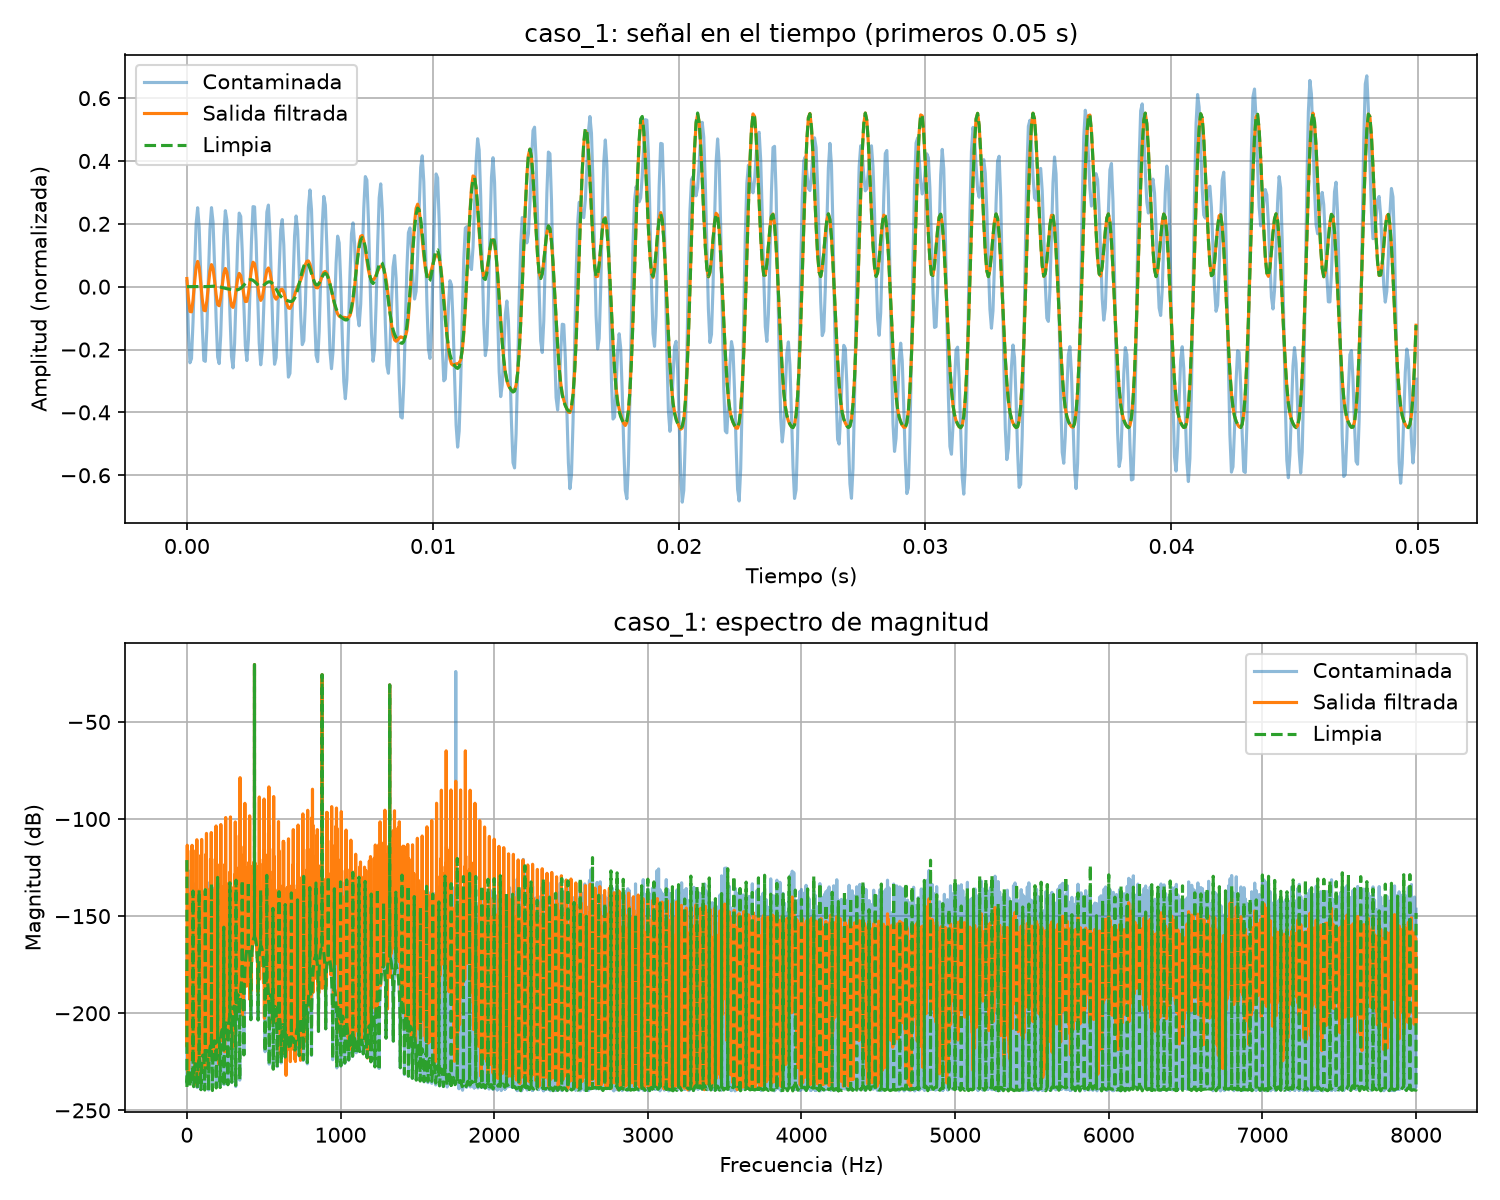

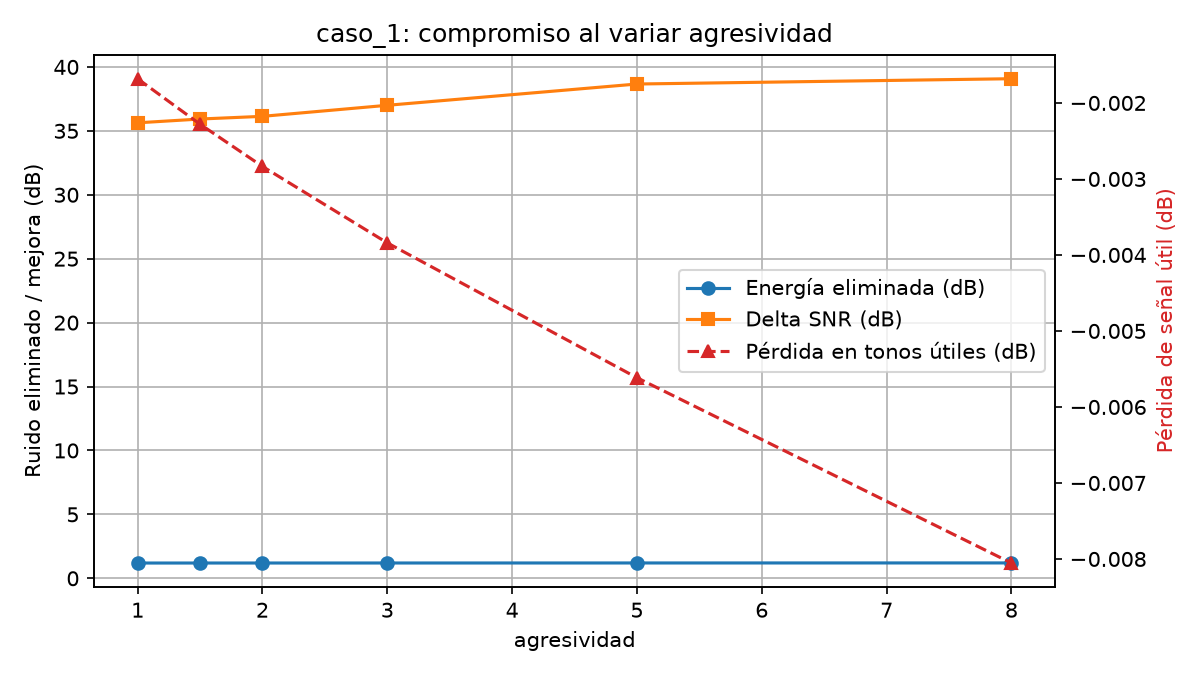

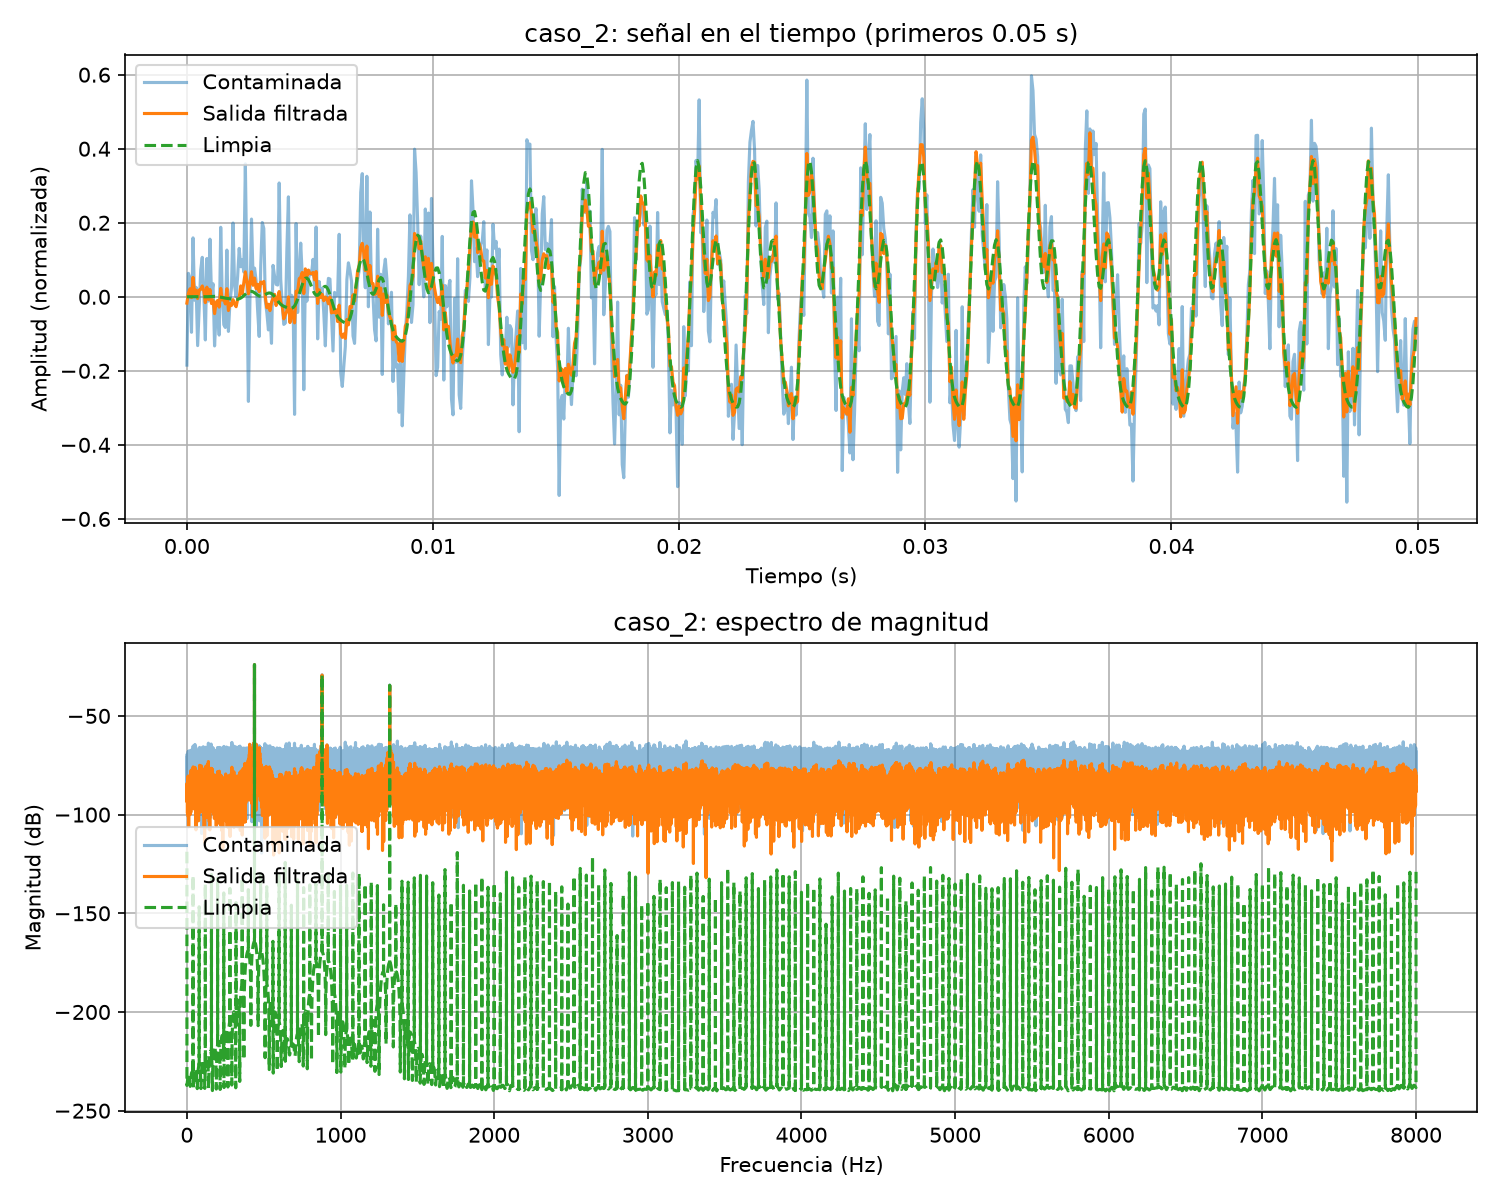

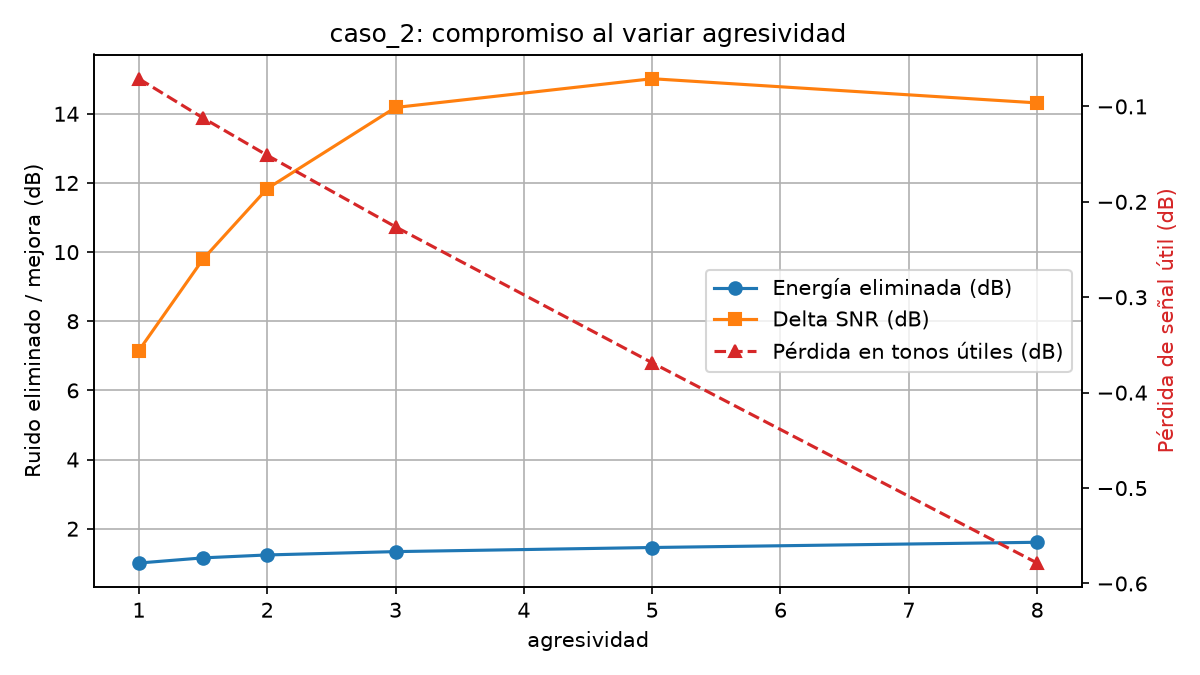

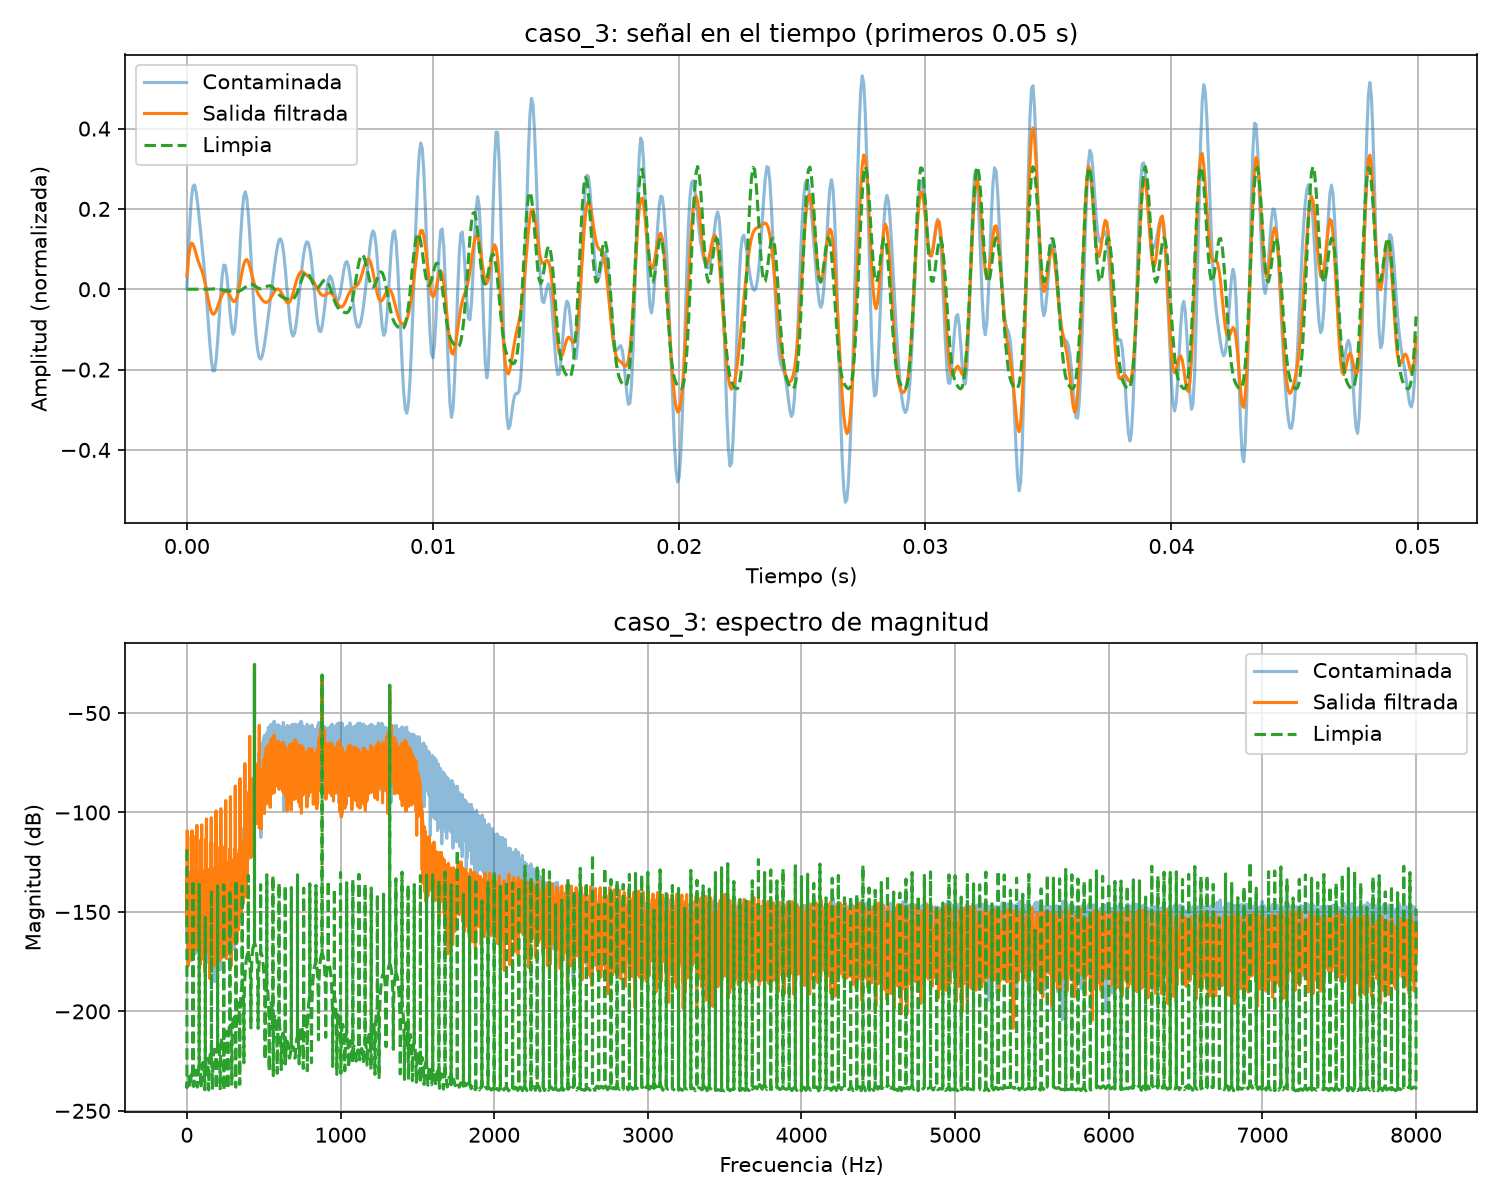

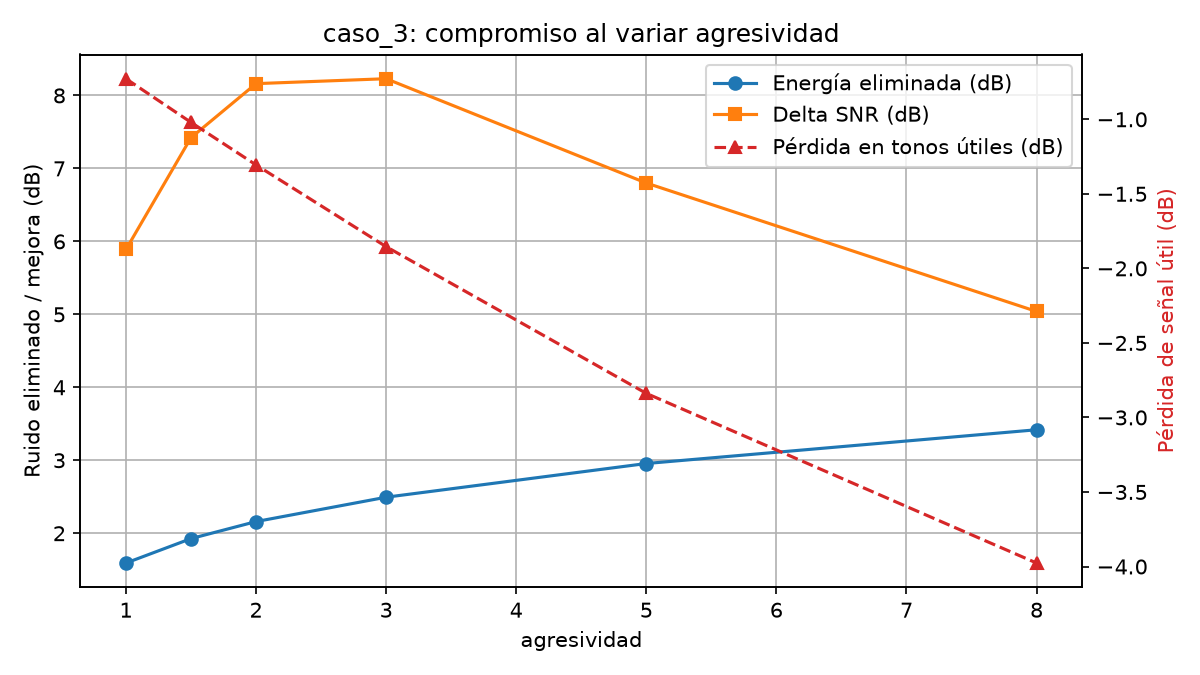

In [7]:
correr_script("filtrado_espectral.py")
for caso in ["caso_1", "caso_2", "caso_3"]:
    mostrar(f"{caso}_resultado_espec.png", f"{caso}_compromiso_espec.png")

## 6. Comparación de métodos (2.5)

Ambos métodos se evalúan con las mismas métricas y sobre el mismo segmento (desde t = 1 s). Los resultados se guardan en `resultados/metricas.csv`.

## 6. Comparación de métodos (2.5)

En esta sección se comparan, con los mismos criterios, la salida del filtro temporal (notch IIR de la sección 4) y la del filtrado espectral (FFT/IFFT de la sección 5) en los tres casos de prueba. Como referencia también se evalúa la señal contaminada sin filtrar.

**Metodología** (`src/comparacion.py`):

- Las tres señales se evalúan sobre el mismo segmento, desde t = 1 s hasta el final. Así se excluye el transitorio inicial del IIR y el arranque de la estimación de ruido del método espectral, y la comparación es justa para ambos métodos.
- **Métricas en el tiempo:** MSE, SNR de salida y mejora ΔSNR = SNR_salida − SNR_entrada.
- **Métricas en frecuencia** (FFT con ventana Hann del segmento completo):
  - *Energía útil conservada (%)*: energía de la salida en ±5 Hz alrededor de 440, 880 y 1320 Hz, relativa a la de la señal limpia.
  - *Atenuación del ruido (dB)*: reducción de energía en la zona del ruido, que se elige según `tipo_ruido` de cada caso (el tono de 1750 Hz, la banda de 500–1500 Hz o todo el espectro), excluyendo los bins útiles.
- **Costo:** tiempo de ejecución por bloque de 512 muestras nuevas (límite de tiempo real: 32 ms a 16 kHz) y memoria aproximada según los búferes de cada método. Los tiempos se miden en la PC, por lo que sirven como comparación relativa y no como predicción para el microcontrolador.

**Salidas:** `resultados/metricas.csv` y `resultados/figuras/comparacion_metodos.png`.

**Resultado principal:** el método espectral obtiene la mayor mejora de SNR en los tres casos. El notch solo es efectivo cuando la interferencia está en 1750 Hz (caso 1), y el método espectral pierde energía útil cuando el ruido comparte banda con la señal (caso 3). El análisis completo está en la sección 2.5 del informe.

In [8]:
import comparacion
comparacion.main()

Segmento evaluado: muestras 16000 en adelante | bloque = 512 muestras nuevas (limite de tiempo real 32 ms a 16 kHz)

caso    ruido   metodo           SNR    dSNR        MSE  E.util%  Aten.dB    t[us]
----------------------------------------------------------------------------------
caso_1  tonal   sin_filtrar     5.01    0.00 3.1473e-02    100.0     0.00        -
caso_1  tonal   temporal       24.46   19.45 3.5734e-04     99.6   194.99      5.3
caso_1  tonal   espectral      41.43   36.43 7.1665e-06     99.9    56.47    121.9
caso_2  blanco  sin_filtrar     5.01    0.00 1.3915e-02    100.7     0.00        -
caso_2  blanco  temporal        5.11    0.10 1.3604e-02    100.3     0.15      5.4
caso_2  blanco  espectral      14.87    9.85 1.4403e-03     98.2    10.00    122.3
caso_3  banda   sin_filtrar     3.03    0.00 1.5133e-02     98.2     0.00        -
caso_3  banda   temporal        3.07    0.04 1.5005e-02     97.8     0.06      5.7
caso_3  banda   espectral      10.55    7.51 2.6826e-

                caso            tipo_ruido                metodo         snr_salida_db          delta_snr_db      energia_util_pct   atenuacion_ruido_db  tiempo_us_por_bloque
              caso_1                 tonal           sin_filtrar                 5.007                   0.0                 100.0                   0.0                      
              caso_1                 tonal              temporal                24.456                19.449                 99.64                194.99                  5.33
              caso_1                 tonal             espectral                41.434                36.426                 99.94                 56.47                121.92
              caso_2                blanco           sin_filtrar                 5.015                   0.0                100.71                   0.0                      
              caso_2                blanco              temporal                 5.113                 0.098                1

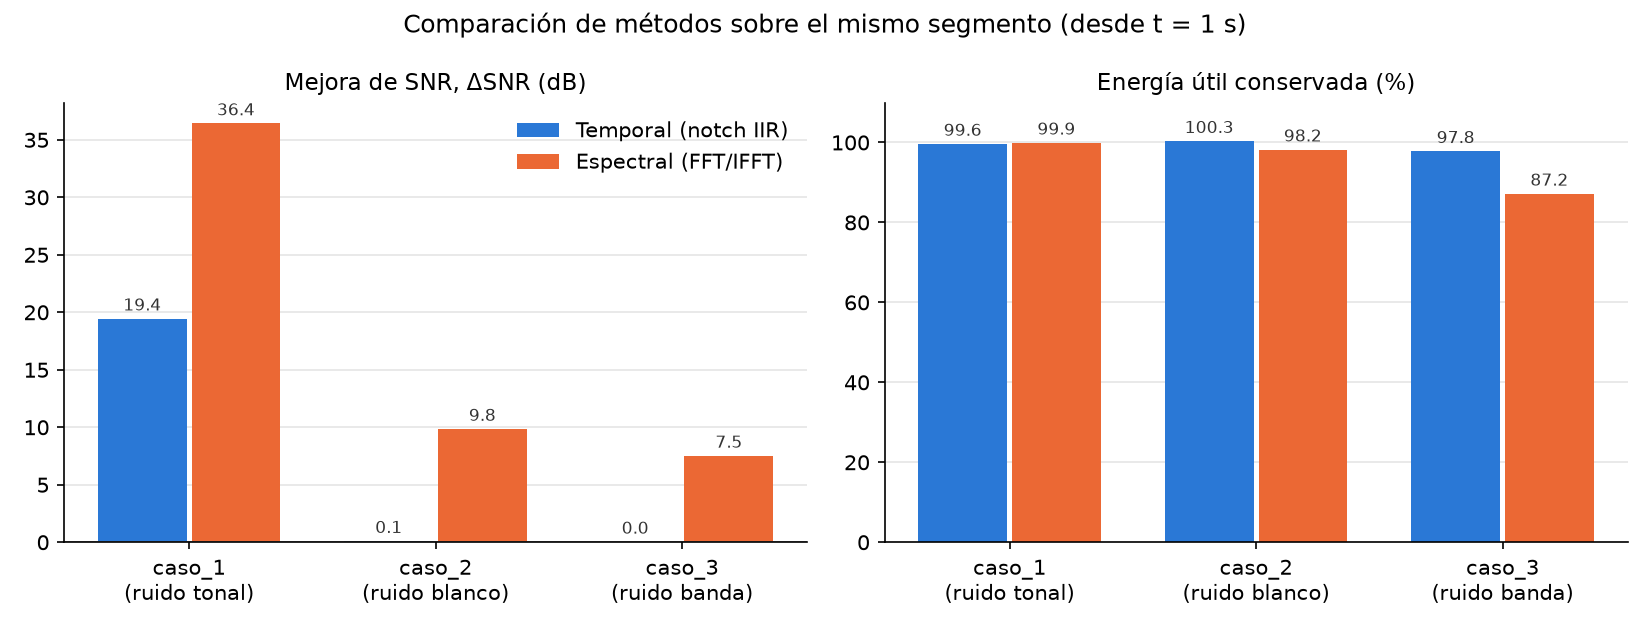

In [9]:
# Tabla de metricas.csv con las columnas principales
with open(RAIZ / "resultados" / "metricas.csv", encoding="utf-8") as f:
    filas = list(csv.DictReader(f))

columnas = ["caso", "tipo_ruido", "metodo", "snr_salida_db", "delta_snr_db",
            "energia_util_pct", "atenuacion_ruido_db", "tiempo_us_por_bloque"]
print("  ".join(f"{c:>20s}" for c in columnas))
for r in filas:
    print("  ".join(f"{r[c]:>20s}" for c in columnas))

mostrar("comparacion_metodos.png", ancho=900)

## 7. Verificación final

Comprueba que se generaron todos los entregables de datos.

In [10]:
esperados = [RAIZ / "resultados" / "metricas.csv", CONFIG]
for caso in ["caso_1", "caso_2", "caso_3"]:
    for nombre in ["01_referencia_limpia.wav", "02_ruido.wav", "03_entrada_contaminada.wav", "metadatos_prueba.json"]:
        esperados.append(PRUEBAS / caso / nombre)

faltantes = [p for p in esperados if not p.exists()]
print(f"Figuras generadas: {len(list(FIGURAS.glob('*.png')))}")
print("Todos los archivos esperados existen." if not faltantes else f"Faltan: {faltantes}")

Figuras generadas: 45
Todos los archivos esperados existen.
